# CONVIVE · Iteration 3 · Quantified research questions

Team 102_A (Convive Lab) · Mobile Data Challenge 2026 · Iteration 3 (10-23 Nov 2026) · WBS 2.2.1, 2.2.2, 3.2.0-3.2.4

The Business Manager asked on 9 Nov for research questions that are **precise and quantified**, with an explicit threshold that tells us how to answer each one with the data, more concrete questions about tourists, and an explanation of the neighbourhoods with very few data. This notebook does exactly that:

1. **2.2.1** builds the aggregated tables (countries, provinces, municipalities, profile, daily neighbourhood visitors, trips between neighbourhoods, coverage).
2. **2.2.2** validates them (totals through two independent paths, unique visitors never summed, coverage, privacy threshold).
3. **3.2.4 / 3.2.1-3.2.3** answer Q1-Q17. For every question: belief → question → metric → **decision rule fixed in advance** → answer → verdict → limitation.
4. **I8** explains the low-data neighbourhoods.

**Rules (NDA).** Outputs show only aggregated values; any count below 15 reads `<15`. Trips and unique visitors are never combined; unique visitors are never summed into people (sums across neighbourhoods are called *presences*). The results describe patterns, not causes.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

import aggregates as A
import research as R
import research_report as RR
import validation as V

pd.set_option("display.max_colwidth", 120, "display.width", 200, "display.max_rows", 80)
RAW_AVAILABLE = A.TOURISM_DIR.exists() and A.MOBILITY_DIR.exists()
print("Raw data on this computer:", RAW_AVAILABLE)

Raw data on this computer: False


## 1. Aggregation data generation (2.2.1)

Reads the monthly CSV files with pandas only (no DuckDB needed), one month at a time, and writes NDA-safe aggregated tables. Mobility is cached per month, so the step can resume.

In [2]:
if RAW_AVAILABLE:
    A.run_tourism()
    A.run_mobility()
else:
    print("No raw data here: using the aggregated tables in", A.OUT_DIR.relative_to(A.HERE))
sorted(p.name for p in A.OUT_DIR.glob("*.csv"))

No raw data here: using the aggregated tables in deliverables/iteration3/2.2.1_aggregates


['coverage_barrio_dataset.csv',
 'm1_incoming_weekday_by_group.csv',
 'm1_name_check.csv',
 'm1_od_year_by_origin.csv',
 'm1_outgoing_month_by_origin.csv',
 't5_barrio_daily_by_origin.csv',
 't6_municipality_barrio_year.csv',
 't6_municipality_city_month.csv',
 't7_province_barrio_year.csv',
 't7_province_city_month.csv',
 't8_country_barrio_year.csv',
 't8_country_city_month.csv',
 't9_profile_barrio_year.csv',
 't9_profile_city_month.csv']

## 2. Aggregated data validation (2.2.2)

In [3]:
V.main()
pd.read_csv(V.OUT_CSV)[["#", "area", "check", "result", "evidence"]]

Validation: 16/17 passed, 0 failed
 #                                                                                                                       check result                                                                          evidence
 1                                                      No exported count of people or trips between 1 and 14 (written as <15)   PASS                                                   23 tables scanned; 0 violations
 2 M1 trips per year and origin are identical through two independent paths (raw CSV with pandas vs clean Parquet with DuckDB)   PASS                12 year x origin totals, 1,920,012,572 trips; largest difference 0
 3                                                         Share of published zero flows (<15 trips) is the same in both paths   PASS 42.4802% vs 42.4802%. Zeros stay 0 with a flag; they are never read as 'no trips'
 4                              T4: the largest neighbourhood never exceeds the city value of T1 (sam

,#,area,check,result,evidence
0,1,Privacy,No exported count of people or trips between 1 and 14 (written as <15),PASS,23 tables scanned; 0 violations
1,2,Totals,M1 trips per year and origin are identical through two independent paths (raw CSV with pandas vs clean Parquet with ...,PASS,"12 year x origin totals, 1,920,012,572 trips; largest difference 0"
2,3,Zeros,Share of published zero flows (<15 trips) is the same in both paths,PASS,42.4802% vs 42.4802%. Zeros stay 0 with a flag; they are never read as 'no trips'
3,4,Not additive,"T4: the largest neighbourhood never exceeds the city value of T1 (same month, origin and type)",PASS,160 month x segment cells; max ratio 0.641
4,5,Not additive,"T4: summing neighbourhoods gives MORE than the city people (so sums are labelled presences, never people)",PASS,"sum of neighbourhoods / city people: median 4.81, range 1.95-5.89"
5,6,Not additive,"T8: country presences >= T1 international people, and the largest single neighbourhood-country cell <= T1",PASS,64 month x type cells; presences / people median 3.64
6,7,Not additive,T5: the largest neighbourhood of each day never exceeds the city value of T2,PASS,2913 day x origin cells; max ratio 0.419
7,8,Coverage,T6: 32 months present (Jan 2023 to Aug 2025),PASS,32 months
8,9,Coverage,T7: 32 months present (Jan 2023 to Aug 2025),PASS,32 months
9,10,Coverage,T8: 32 months present (Jan 2023 to Aug 2025),PASS,32 months


## 3. Answers

`R.THRESHOLDS` holds every decision rule. They were written before the answers were computed: a rule decides the verdict, not the number.

In [4]:
t, r = R.run_all()
answers = RR.answers_table(r)


def show(qid):
    row = answers.set_index("id").loc[qid]
    display(Markdown(f"### {qid} · {row.question}\n\n*Belief:* “{row.belief}”  \n*Metric:* {row.metric}  \n"
                     f"*Decision rule:* {row.decision_rule}\n\n**Answer.** {row.answer}\n\n**Verdict: {row.verdict}.**  \n"
                     f"*Limitation:* {row.limitation}"))


answers[["id", "belief", "verdict"]]

,id,belief,verdict
0,Q1,Tourists are everywhere in Barcelona.,Concentrated for all visitors; concentrated for international tourists
1,Q2,Tourism is only a summer problem.,Moderate seasonality overall; moderate seasonality for international tourists
2,Q3,Most visitors are foreign tourists.,"Partly: international majority in 22 of 32 months, the rule needs 24; the top 5 countries hold half of international..."
3,Q4,Visitors flood the city at weekends.,Fewer at weekends (<= -5%)
4,Q5,Tourism keeps growing every year.,Keeps growing overall (+2% rule); keeps growing for international tourists; keeps falling for national visitors
5,Q6,"In tourist neighbourhoods, visitors' movement outnumbers residents'.",True in 9 of 10 tourist neighbourhoods; false city-wide
6,Q7,Tourists only stay for a weekend.,Holds: most tourists stay 1-2 nights per week
7,Q8,The tourist neighbourhoods are the same all year round.,Stable ranking all year
8,Q9,Big events and holidays create visible peaks.,7 peak days and 25 low days found
9,Q10,Regional day-trippers go to the same places as foreign tourists.,Different places: regional day-trippers do not follow foreign tourists


### 3.1 Quantified Q1-Q6 (3.2.4)

In [5]:
show("Q1")

### Q1 · How concentrated are visitors across the 73 neighbourhoods?

*Belief:* “Tourists are everywhere in Barcelona.”  
*Metric:* N50: smallest number of neighbourhoods holding 50% of visitor presences (mean monthly visitors per neighbourhood); top-10 share; Gini  
*Decision rule:* Visitors are CONCENTRATED if 50% of visitor presences fall in at most 11 neighbourhoods (15% of 73), i.e. N50 <= 11. SPREAD if N50 >= 22 (30% of 73). In between: MODERATELY concentrated.

**Answer.** Half of all visitor presences fall in 10 of 73 neighbourhoods (14%); N50 ranges 9-12 across the 32 months. The 10 largest hold 50.1% (Gini 0.59). International overnight tourists are more concentrated: N50 = 8 (60.5% in the top 10: la Dreta de l'Eixample, el Barri Gòtic, la Sagrada Família). Regional visitors are the most spread (N50 = 15).

**Verdict: Concentrated for all visitors; concentrated for international tourists.**  
*Limitation:* Neighbourhood values are not additive: shares are of presences (person x neighbourhood), not of people.

In [6]:
r['Q1']['table'].round(3)

,origin,type,n50,n50_month_min,n50_month_max,n80,top10_share,gini,top3,verdict
0,All visitors,all,10,9,12,27,0.501,0.589,"la Dreta de l'Eixample, el Barri Gòtic, la Sagrada Família",Concentrated
1,International,all,7,7,8,19,0.621,0.696,"la Dreta de l'Eixample, el Barri Gòtic, la Sagrada Família",Concentrated
2,International,tourists,8,7,8,20,0.605,0.693,"la Dreta de l'Eixample, el Barri Gòtic, la Sagrada Família",Concentrated
3,International,excursionists,6,5,7,18,0.664,0.716,"la Dreta de l'Eixample, el Barri Gòtic, la Marina del Prat Vermell",Concentrated
4,National,all,11,10,12,27,0.474,0.580,"la Dreta de l'Eixample, Sants, el Barri Gòtic",Concentrated
5,Regional,all,15,14,16,32,0.380,0.491,"la Dreta de l'Eixample, Sants, el Barri Gòtic",Moderately concentrated


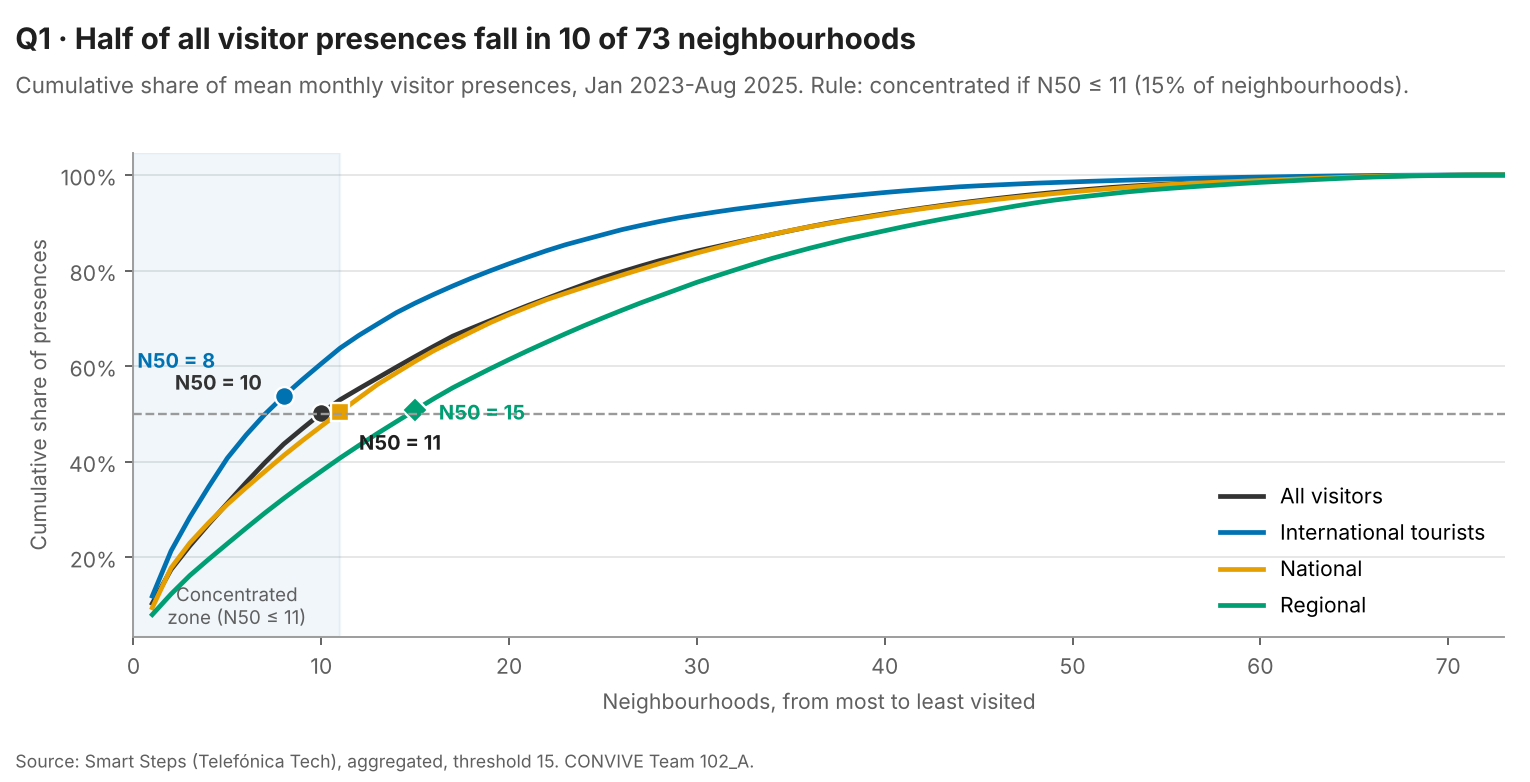

In [7]:
Image(filename=str(R.OUT / "figures" / "q1_concentration.png"))

In [8]:
show("Q2")

### Q2 · How much higher are June-August than the rest of the year, by origin?

*Belief:* “Tourism is only a summer problem.”  
*Metric:* Ratio of the June-August monthly mean to the mean of the other nine months, full years 2023 and 2024; months within 90% of the peak  
*Decision rule:* SUMMER-ONLY pattern if the June-August mean is at least 30% above the mean of the other nine months (ratio >= 1.30) in both full years. MODERATE seasonality if 1.10 to 1.30. NO marked seasonality if < 1.10. A month counts as a HIGH month if it is at least 90% of that year's peak.

**Answer.** June-August is 1.13x (2023) and 1.14x (2024) the other months for all visitors; 7 months of 2024 reach 90% of the peak (Apr, May, Jun, Jul, Aug, Sep, Oct), 4 of them outside summer. International tourists are the most seasonal (1.23x and 1.25x; peak-to-trough 1.71 in 2024).

**Verdict: Moderate seasonality overall; moderate seasonality for international tourists.**  
*Limitation:* 2025 covers January-August only and has no full-year ratio.

In [9]:
r['Q2']['table'].round(3)

,origin,type,year,summer_vs_rest,peak_month,low_month,peak_to_trough,high_months,n_high_months,high_outside_summer,verdict
0,All visitors,all,2023,1.132,Jul,Feb,1.436,"Apr, May, Jun, Jul, Aug, Sep, Oct",7,4,Moderate seasonality
1,All visitors,all,2024,1.137,Jul,Jan,1.399,"Apr, May, Jun, Jul, Aug, Sep, Oct",7,4,Moderate seasonality
2,International,all,2023,1.330,Aug,Jan,1.993,"Jul, Aug, Oct",3,1,Summer-only pattern
3,International,all,2024,1.301,Jul,Jan,1.874,"May, Jul, Aug, Oct",4,2,Summer-only pattern
4,International,tourists,2023,1.232,Jul,Jan,1.778,"Jul, Aug, Sep, Oct",4,2,Moderate seasonality
5,International,tourists,2024,1.245,Jul,Jan,1.708,"May, Jun, Jul, Aug, Sep, Oct",6,3,Moderate seasonality
6,National,all,2023,0.914,May,Aug,1.407,"Mar, Apr, May, Jun, Oct, Dec",6,5,No marked seasonality
7,National,all,2024,0.943,Dec,Aug,1.365,"Mar, Apr, May, Jun, Dec",5,4,No marked seasonality
8,Regional,all,2023,0.934,Dec,Aug,1.255,"Jan, Mar, Apr, May, Jun, Jul, Oct, Nov, Dec",9,7,No marked seasonality
9,Regional,all,2024,0.940,Dec,Aug,1.252,"Jan, Mar, Apr, May, Jun, Oct, Nov, Dec",8,7,No marked seasonality


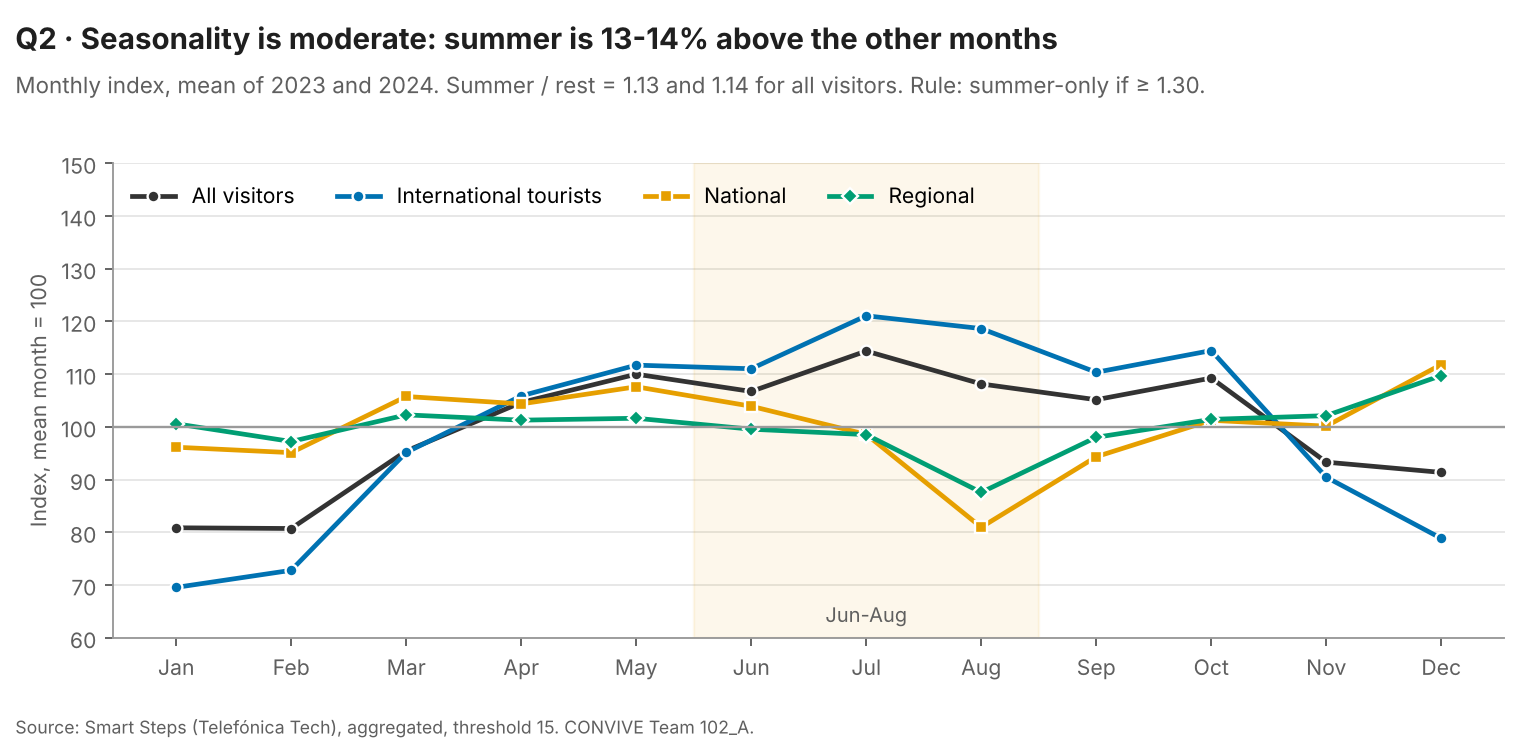

In [10]:
Image(filename=str(R.OUT / "figures" / "q2_seasonality.png"))

In [11]:
show("Q3")

### Q3 · In how many months are international visitors the majority, and from which countries?

*Belief:* “Most visitors are foreign tourists.”  
*Metric:* Monthly international share of unique visitors (T1); share of international presences by country of residence (T8)  
*Decision rule:* Visitors are MOSTLY FOREIGN if international visitors are more than 50% of monthly unique visitors (T1) in at least 75% of the months (24 of 32). Countries: a FEW COUNTRIES dominate if the top 5 countries hold at least 50% of international presences (T8).

**Answer.** International visitors are 55.2% of monthly unique visitors on average and above 50% in 22 of 32 months (range 43.1%-66.2%). Among overnight tourists they are 81.9%. By country of residence (T8) the top 5 are France 11.4%, United Kingdom 11.3%, United States 11.1%, Germany 9.7%, Italy 8.7%: together 52.1% of international presences; small countries grouped as NA are 0.4%.

**Verdict: Partly: international majority in 22 of 32 months, the rule needs 24; the top 5 countries hold half of international presences.**  
*Limitation:* Country shares are of presences; countries below 15 people per neighbourhood are grouped as NA.

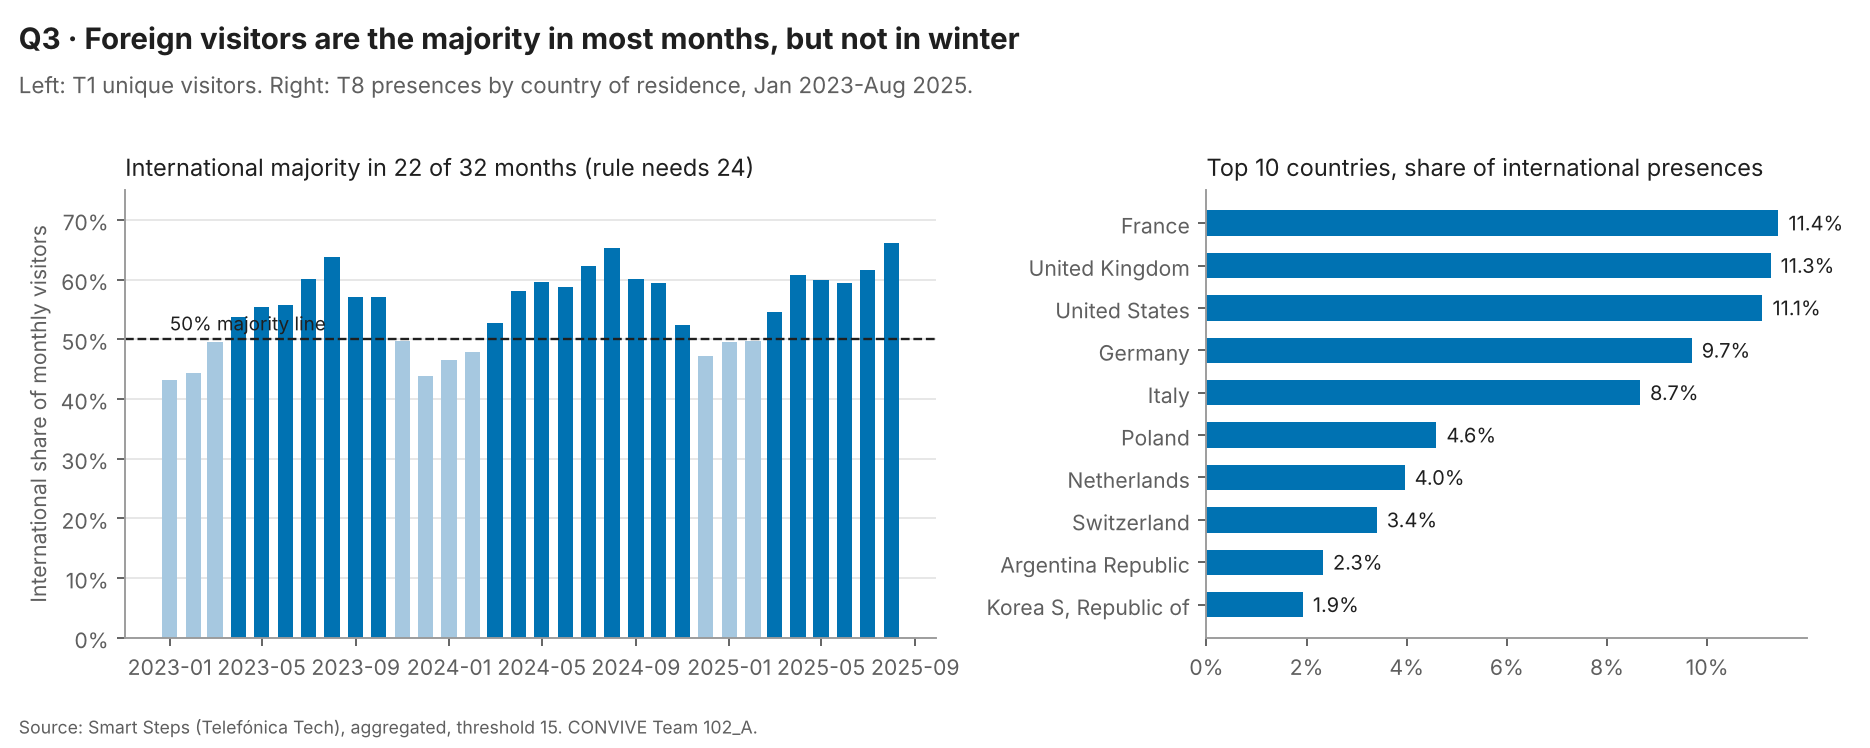

In [12]:
Image(filename=str(R.OUT / "figures" / "q3_origin_countries.png"))

In [13]:
show("Q4")

### Q4 · Are mean daily visitors on Saturday-Sunday at least 10% above Monday-Friday?

*Belief:* “Visitors flood the city at weekends.”  
*Metric:* Weekend vs weekday mean daily unique visitors, city (T2) and each neighbourhood (T5); 95% bootstrap interval  
*Decision rule:* Visitors FLOOD the city at weekends if the mean daily unique visitors on Saturday and Sunday is at least 10% above Monday to Friday (ratio >= 1.10). NO DIFFERENCE if within +/-5%. FEWER at weekends if <= -5%. The same rule is applied to each neighbourhood (T5).

**Answer.** City (T2): 497,841 visitors per weekend day vs 539,023 per weekday, -7.6% (95% bootstrap interval -9.0% to -6.3%). International +0.3%, national -14.4%, regional -13.0%. Neighbourhoods (T5): 7 of 73 meet the weekend-flood rule (el Poble-sec, la Barceloneta, la Vila Olímpica del Poblenou, Sant Pere, Santa Caterina i la Ribera, Can Baró); 48 have fewer visitors at weekends.

**Verdict: Fewer at weekends (<= -5%).**  
*Limitation:* Daily values are never summed into weeks; 3 days are missing; T5 uses published values only.

In [14]:
r['Q4']['table'].round(3)

,origin,type,weekday_mean,weekend_mean,weekend_change,ci_low,ci_high,verdict
0,All visitors,all,539023.367,497841.469,-0.076,-0.090,-0.063,Fewer at weekends (<= -5%)
1,International,all,227484.588,228148.451,0.003,-0.023,0.027,No difference (within ±5%)
2,International,tourists,113908.486,114381.173,0.004,-0.021,0.028,No difference (within ±5%)
3,National,all,92654.803,79315.978,-0.144,-0.163,-0.126,Fewer at weekends (<= -5%)
4,Regional,all,218883.977,190377.040,-0.130,-0.153,-0.109,Fewer at weekends (<= -5%)


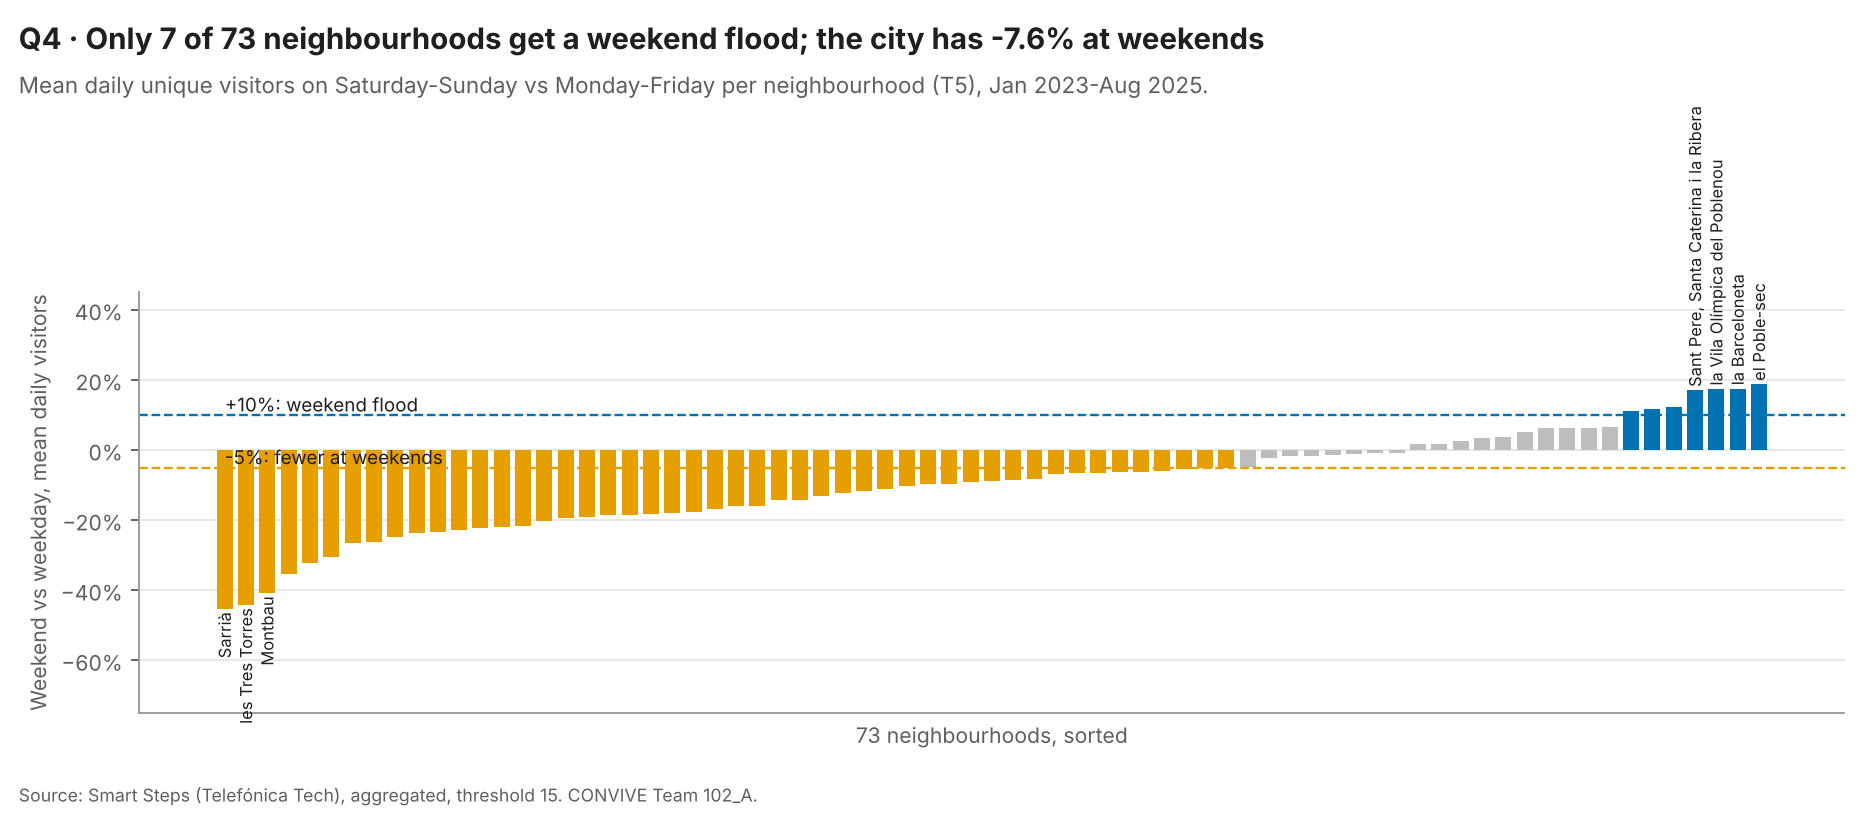

In [15]:
Image(filename=str(R.OUT / "figures" / "q4_weekend_barrios.png"))

In [16]:
show("Q5")

### Q5 · Did January-August visitors grow by more than 2% in both 2024 and 2025?

*Belief:* “Tourism keeps growing every year.”  
*Metric:* Change in the January-August monthly mean, 2023->2024 and 2024->2025, city and neighbourhoods (base >= 1,000)  
*Decision rule:* Visitors KEEP GROWING if the January-August mean grows by more than 2% in BOTH intervals (2023->2024 and 2024->2025). STABLE if both changes are within +/-2%. Otherwise MIXED. A neighbourhood is counted only with a base of at least 1,000 visitors per month.

**Answer.** All visitors: +5.1% (2023->2024) and +2.3% (2024->2025), January-August means. International tourists +14.7% and +3.7%; national visitors -4.9% and -2.6%. Neighbourhoods with a base of 1,000+: 25 keep growing, 1 stable, 5 keep falling, 42 mixed (of 73).

**Verdict: Keeps growing overall (+2% rule); keeps growing for international tourists; keeps falling for national visitors.**  
*Limitation:* Two intervals cannot prove a long-term trend; Feb 2024, Apr 2025 and May 2025 miss one day.

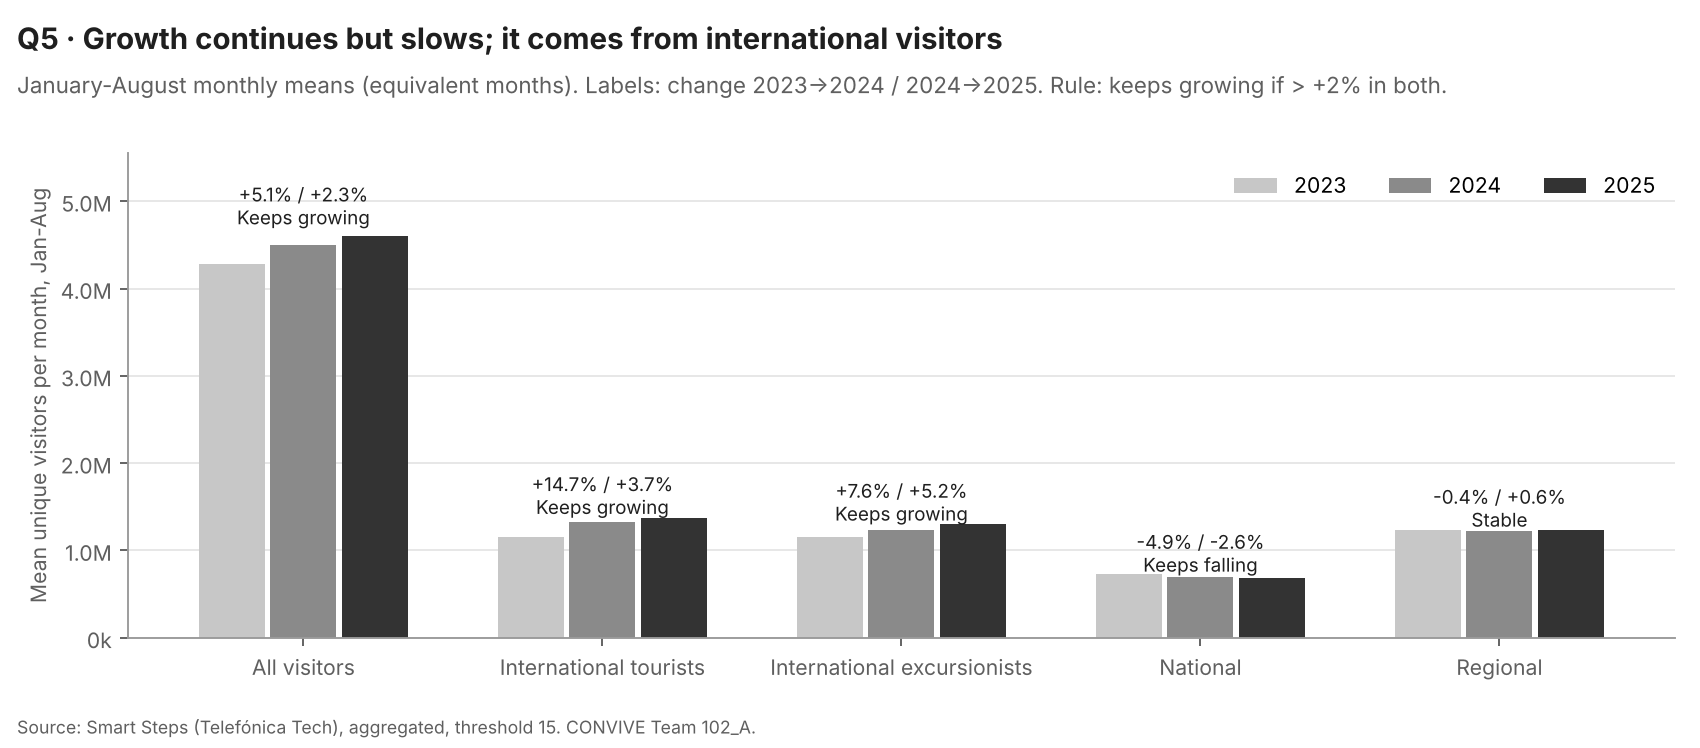

In [17]:
Image(filename=str(R.OUT / "figures" / "q5_growth.png"))

In [18]:
show("Q6")

### Q6 · In the 10 most-visited neighbourhoods, do visitors make more than 50% of incoming trips?

*Belief:* “In tourist neighbourhoods, visitors' movement outnumbers residents'.”  
*Metric:* Visitor share of incoming trips (M1), with bounds that treat each published 0 as 0-14 trips  
*Decision rule:* Tourist neighbourhoods = the 10 neighbourhoods with most mean monthly visitors (T4). In a neighbourhood visitors' trips OUTNUMBER residents' if the visitor share of incoming trips (M1) is above 50%, and ROBUSTLY so if even the low bound (published zeros counted as 14 resident trips) is above 50%.

**Answer.** In 9 of the 10 tourist neighbourhoods visitors make more than half of incoming trips (9 robustly): el Barri Gòtic 70.5%, Sant Pere, Santa Caterina i la Ribera 64.6%, la Barceloneta 60.5%, la Marina del Prat Vermell 60.0%, el Raval 57.8%, Sants 55.6%, el Poble-sec 55.5%, la Dreta de l'Eixample 54.7%, la Sagrada Família 53.0%. The others stay below 50% (lowest: l'Antiga Esquerra de l'Eixample 45.6%). City-wide, visitors make 44.7% of trips between neighbourhoods; 11 of 73 neighbourhoods are above 50%.

**Verdict: True in 9 of 10 tourist neighbourhoods; false city-wide.**  
*Limitation:* Trips, not people. Trips inside a neighbourhood are excluded.

In [19]:
r['Q6']['table'].round(3)

,cod_barrio,barrio_name,distrito_name,visitor_trips,resident_trips,visitor_share,share_low,share_high
1,080190102,el Barri Gòtic,Ciutat Vella,61406695.0,25650966.0,0.705,0.705,0.708
3,080190104,"Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,34987364.0,19135608.0,0.646,0.645,0.653
2,080190103,la Barceloneta,Ciutat Vella,24017225.0,15668260.0,0.605,0.603,0.615
11,080190302,la Marina del Prat Vermell,Sants-Montjuïc,18015858.0,12006508.0,0.600,0.598,0.614
0,080190101,el Raval,Ciutat Vella,38125749.0,27876272.0,0.578,0.577,0.583
17,080190308,Sants,Sants-Montjuïc,37906248.0,30314171.0,0.556,0.555,0.560
10,080190301,el Poble-sec,Sants-Montjuïc,30185904.0,24169168.0,0.555,0.554,0.563
6,080190203,la Dreta de l'Eixample,Eixample,131562714.0,108739334.0,0.547,0.547,0.548
5,080190202,la Sagrada Família,Eixample,33666280.0,29832033.0,0.530,0.530,0.535
7,080190204,l'Antiga Esquerra de l'Eixample,Eixample,30822942.0,36739002.0,0.456,0.456,0.462


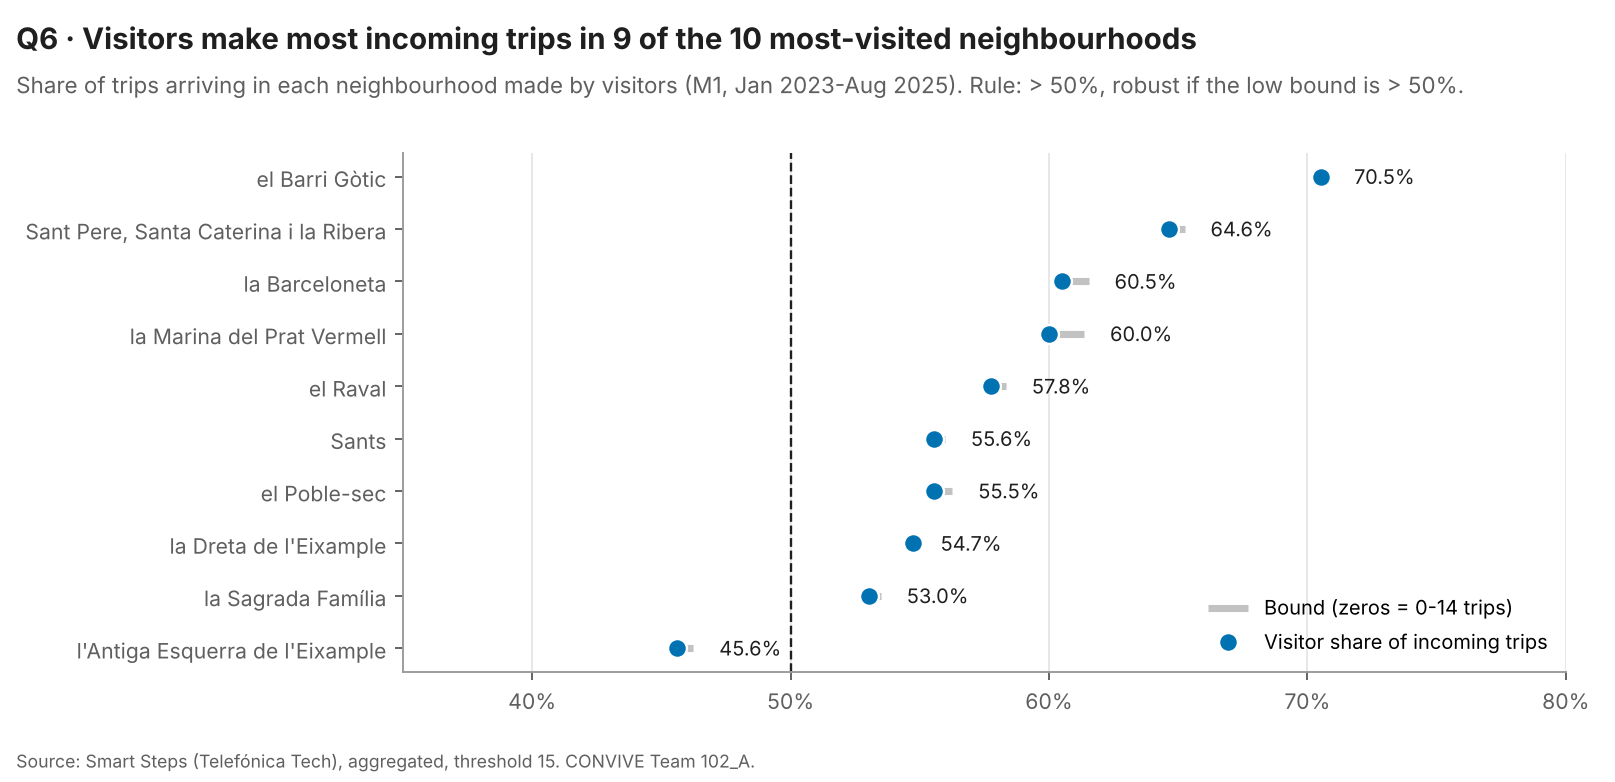

In [20]:
Image(filename=str(R.OUT / "figures" / "q6_tourist_barris.png"))

### 3.2 Who visits (3.2.1 exploratory analysis)

In [21]:
show("Q11")

### Q11 · Do the top 5 countries hold at least half of international tourists?

*Belief:* “International visitors come from a few countries.”  
*Metric:* Share of international presences by country, tourists and excursionists; leading country per neighbourhood  
*Decision rule:* Same as Q3: a few countries dominate if the top 5 hold at least 50% of international presences.

**Answer.** Among international overnight tourists the top 5 countries hold 52.0% (United States 12.7%, United Kingdom 11.9%, France 9.8%, Germany 9.3%, Italy 8.4%). In 2024 the leading country is France in 43 of 73 neighbourhoods, United States in 13.

**Verdict: A few countries dominate.**  
*Limitation:* Small countries are grouped as NA in each neighbourhood.

In [22]:
show("Q12")

### Q12 · Is Madrid at least half of national visitors?

*Belief:* “National visitors are mostly from Madrid.”  
*Metric:* Share of national presences by province of residence  
*Decision rule:* National visitors are MOSTLY FROM MADRID if Madrid is at least 50% of national presences (T7). Madrid is the LARGEST single origin if it ranks first.

**Answer.** Top provinces of national visitors (presences): Girona 16.8%, Madrid 16.8%, Tarragona 14.9%, Lleida 6.8%, Balears, Illes 5.8%. Madrid is 16.8%; the other three Catalan provinces together 38.5%.

**Verdict: Not mostly from Madrid (16.8%); Girona and Madrid are level as the largest.**  
*Limitation:* 'National' excludes the province of Barcelona (those are regional).

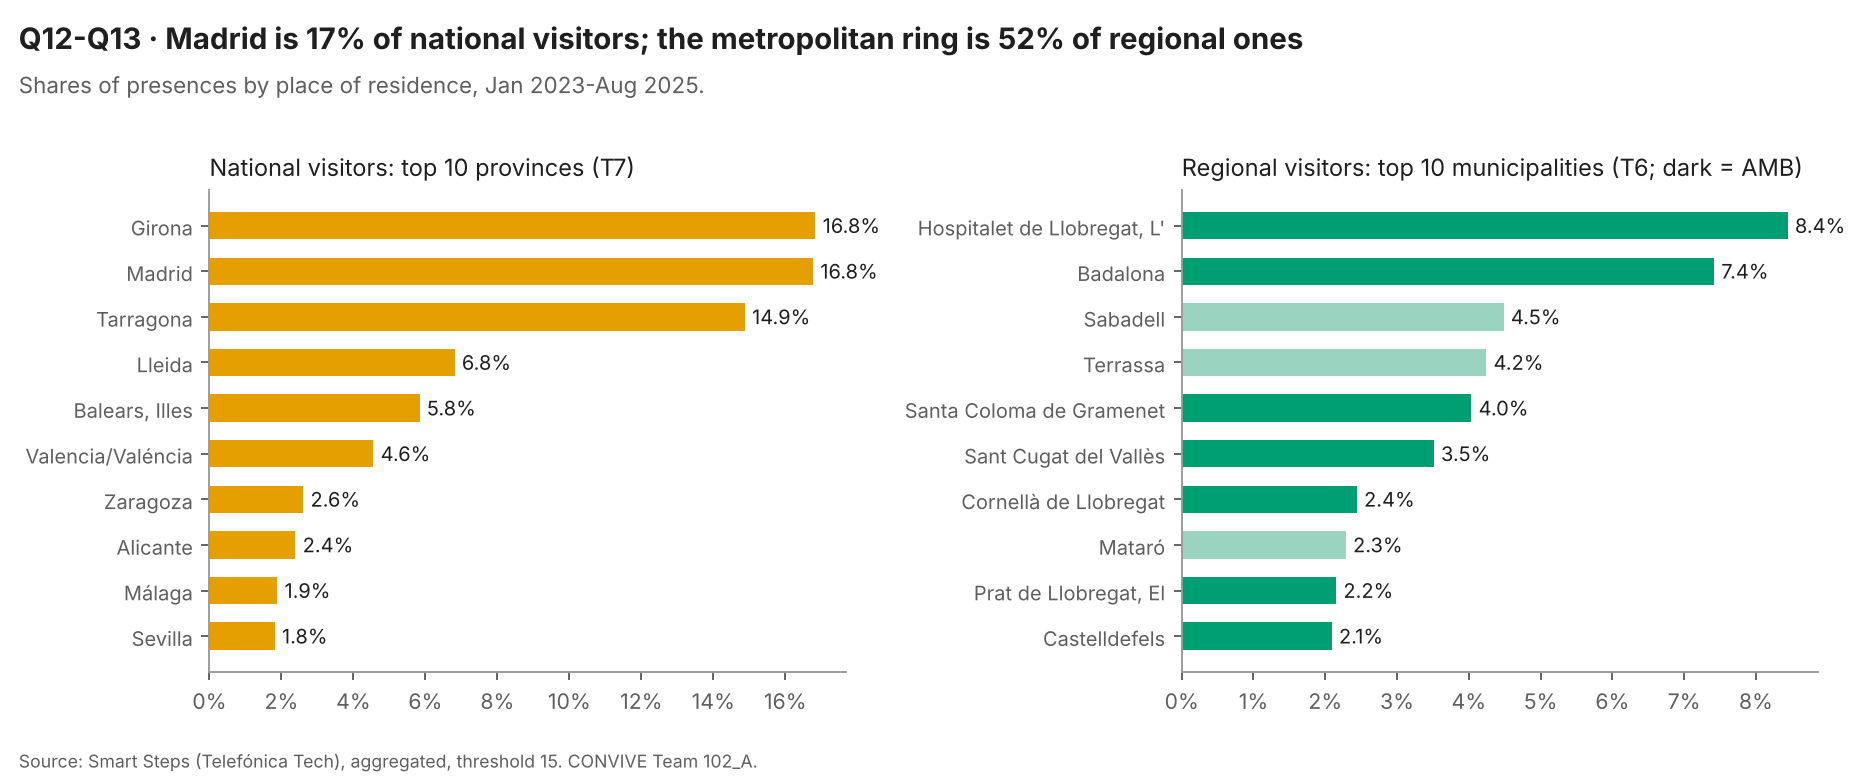

In [23]:
Image(filename=str(R.OUT / "figures" / "q12_q13_residence.png"))

In [24]:
show("Q13")

### Q13 · Do the other 35 AMB municipalities send at least half of regional visitors?

*Belief:* “Regional visitors come from the metropolitan ring.”  
*Metric:* Share of regional presences by municipality of residence  
*Decision rule:* Regional visitors come MOSTLY FROM THE METROPOLITAN RING if the 35 other municipalities of the Àrea Metropolitana de Barcelona hold at least 50% of regional presences (T6).

**Answer.** The 35 other AMB municipalities hold 52.5% of regional presences (35 of 35 found by name). Top: Hospitalet de Llobregat, L' 8.4%, Badalona 7.4%, Sabadell 4.5%, Terrassa 4.2%, Santa Coloma de Gramenet 4.0%.

**Verdict: Mostly from the metropolitan ring.**  
*Limitation:* M3 (trips) is not used because of the repeated keys (I7).

In [25]:
show("Q14")

### Q14 · Are at least half aged 18-39, and at least half high or medium-high income?

*Belief:* “Visitors are young and high-income.”  
*Metric:* Shares of presences by age group, income level and gender  
*Decision rule:* Visitors are YOUNG if the 18-39 age groups hold at least 50% of presences, and HIGH-INCOME if the 'Alto' and 'Medio-Alto' income levels hold at least 50% (T9, national and regional only).

**Answer.** National and regional visitors (T9 has no international rows, issue I9): 18-39 years 36.0%, 60+ 27.5%; high or medium-high income 76.4%, low income 4.2%; women 49.2%.

**Verdict: Not young (36% aged 18-39), but high-income (76% high or medium-high); national and regional only.**  
*Limitation:* T9 has no international visitors (I9): national and regional only.

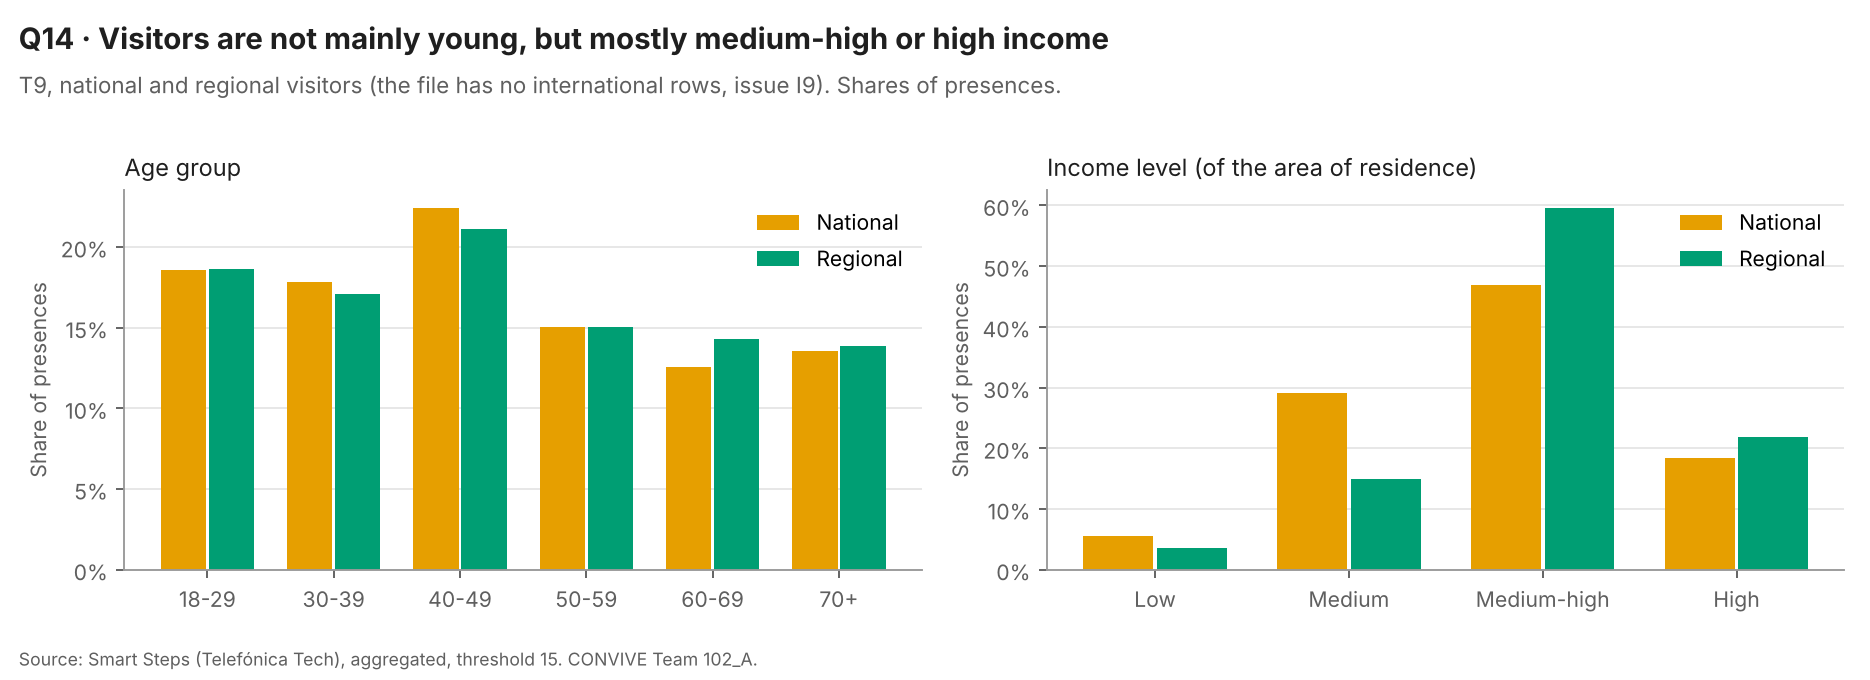

In [26]:
Image(filename=str(R.OUT / "figures" / "q14_profile.png"))

In [27]:
show("Q17")

### Q17 · Which country markets grew more than 20% (January-August 2023->2025)?

*Belief:* “The tourist mix is always the same countries.”  
*Metric:* Change in January-August presences per country with at least 1% of presences  
*Decision rule:* A country market is GROWING FAST if its January-August presences grew by more than 20% between 2023 and 2025. Only countries with at least 1% of international presences in 2023 are ranked.

**Answer.** 9 of 18 country markets with at least 1% of presences grew by more than 20% (January-August, 2023 to 2025): Poland +119.0%, Argentina Republic +110.7%, Canada +59.2%, Turkey +50.6%, Korea S, Republic of +49.4%, United States +35.5%. Lowest: United Kingdom -13.4%, Germany -16.6%, Mexico -51.2%.

**Verdict: 9 fast-growing markets.**  
*Limitation:* Presences, not people; equivalent months only.

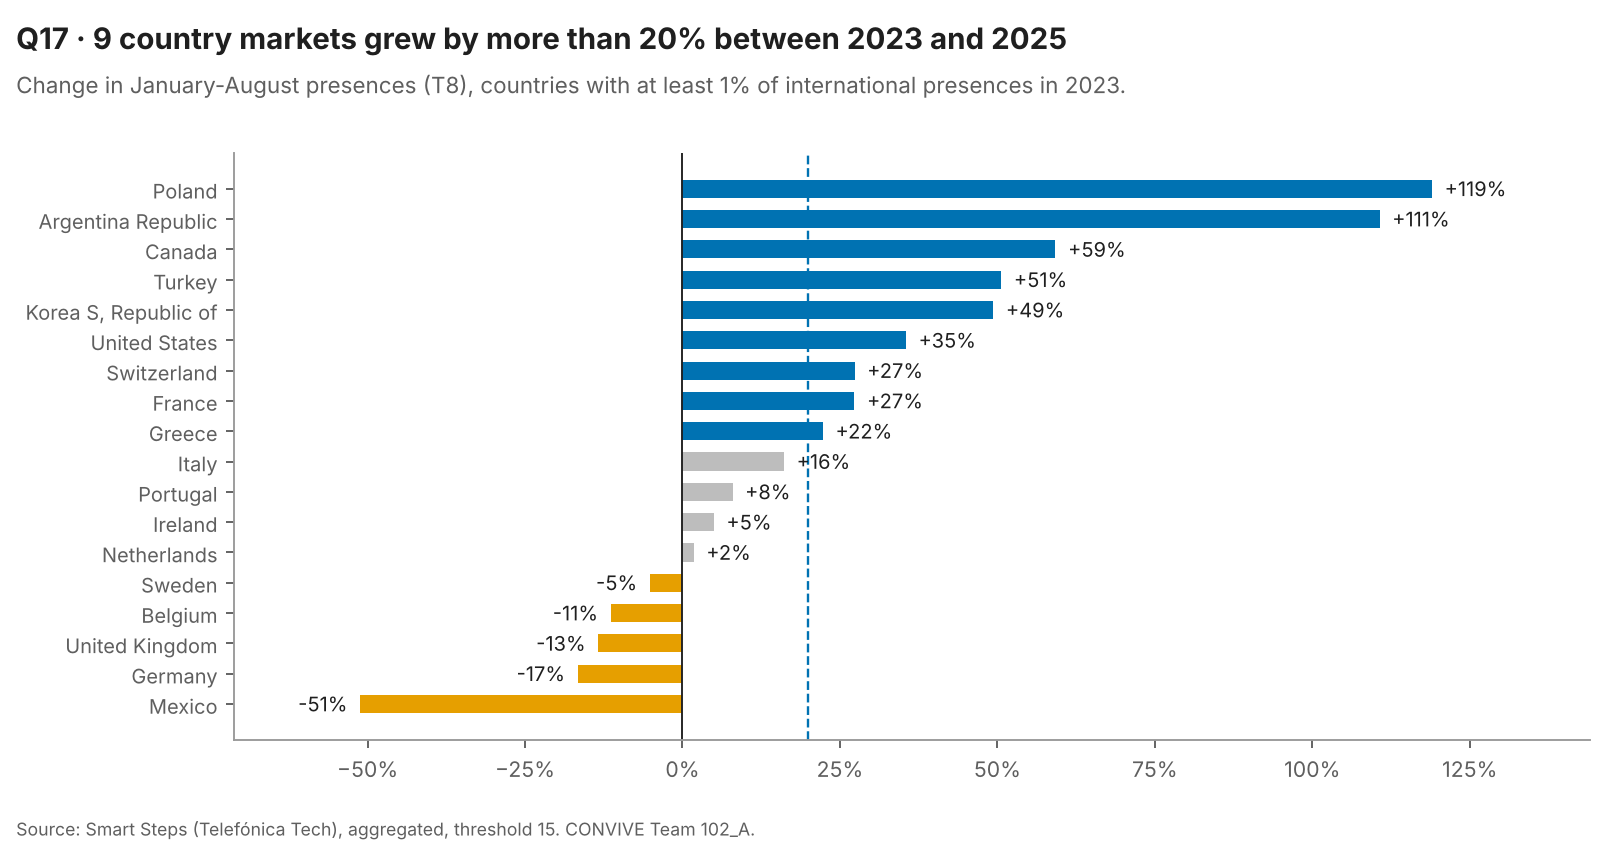

In [28]:
Image(filename=str(R.OUT / "figures" / "q17_country_growth.png"))

### 3.3 Where (3.2.2 geographic analysis)

In [29]:
show("Q16")

### Q16 · Is N50 of international tourists at least 2 neighbourhoods lower than for international excursionists?

*Belief:* “Overnight tourists crowd the same few places more than day-trippers.”  
*Metric:* N50 (see Q1) by visitor type  
*Decision rule:* Overnight tourists are MORE CONCENTRATED than excursionists if their N50 (see Q1) is at least 2 neighbourhoods lower.

**Answer.** N50 is 8 neighbourhoods for international tourists and 6 for international excursionists (gap -2); top-10 share 60.5% vs 66.4%.

**Verdict: No: international excursionists are even more concentrated.**  
*Limitation:* Same as Q1.

In [30]:
show("Q8")

### Q8 · Does the top 10 change between the peak and the lowest month?

*Belief:* “The tourist neighbourhoods are the same all year round.”  
*Metric:* Top-10 overlap and Spearman rank correlation between the peak and the lowest month  
*Decision rule:* The ranking is STABLE across seasons if at least 8 of the top 10 neighbourhoods of the peak month are also in the top 10 of the lowest month, and the Spearman rank correlation is at least 0.90.

**Answer.** 2024: 9 of the top 10 in Jul (peak) are also top 10 in Jan (low); Spearman 0.986. Largest rank moves: Can Peguera (57->69), Sant Andreu (17->26), la Vall d'Hebron (58->50).

**Verdict: Stable ranking all year.**  
*Limitation:* Monthly values only.

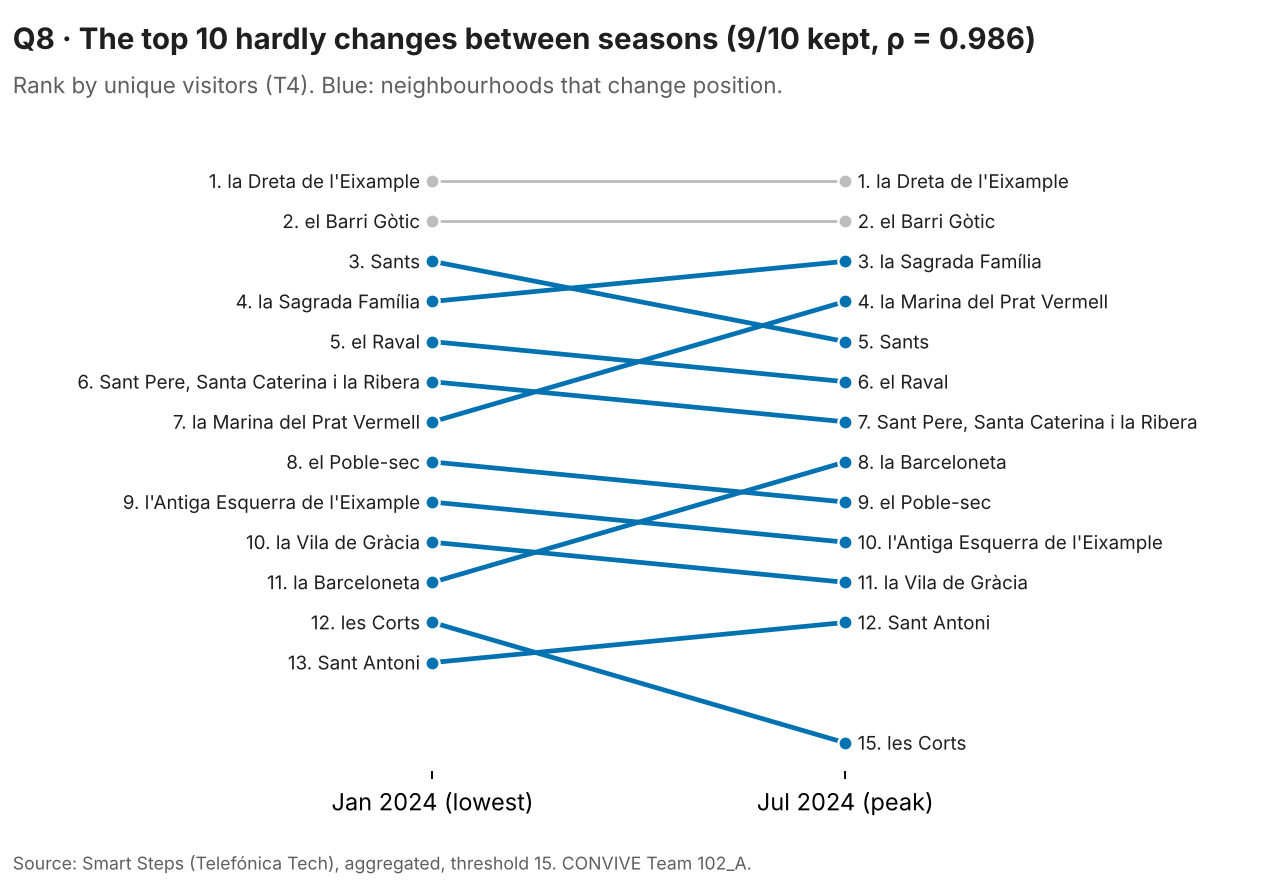

In [31]:
Image(filename=str(R.OUT / "figures" / "q8_rank_season.png"))

In [32]:
show("Q10")

### Q10 · Do the top-10 neighbourhoods of each origin coincide (7 of 10)?

*Belief:* “Regional day-trippers go to the same places as foreign tourists.”  
*Metric:* Top-10 overlap between origins; location quotient (LQ) per neighbourhood and origin  
*Decision rule:* Origins go to the SAME PLACES if at least 7 of the top 10 neighbourhoods by mean monthly visitors coincide between two origins. A neighbourhood is SPECIALISED in an origin if LQ >= 1.25.

**Answer.** Overlap of the top-10 neighbourhoods: international-national 8/10, international-regional 5/10, national-regional 7/10. Neighbourhoods specialised (LQ >= 1.25): international 10, national 13, regional 45. Highest international LQ: la Salut (1.63); highest regional LQ: Ciutat Meridiana (2.50).

**Verdict: Different places: regional day-trippers do not follow foreign tourists.**  
*Limitation:* LQ uses presences, not people.

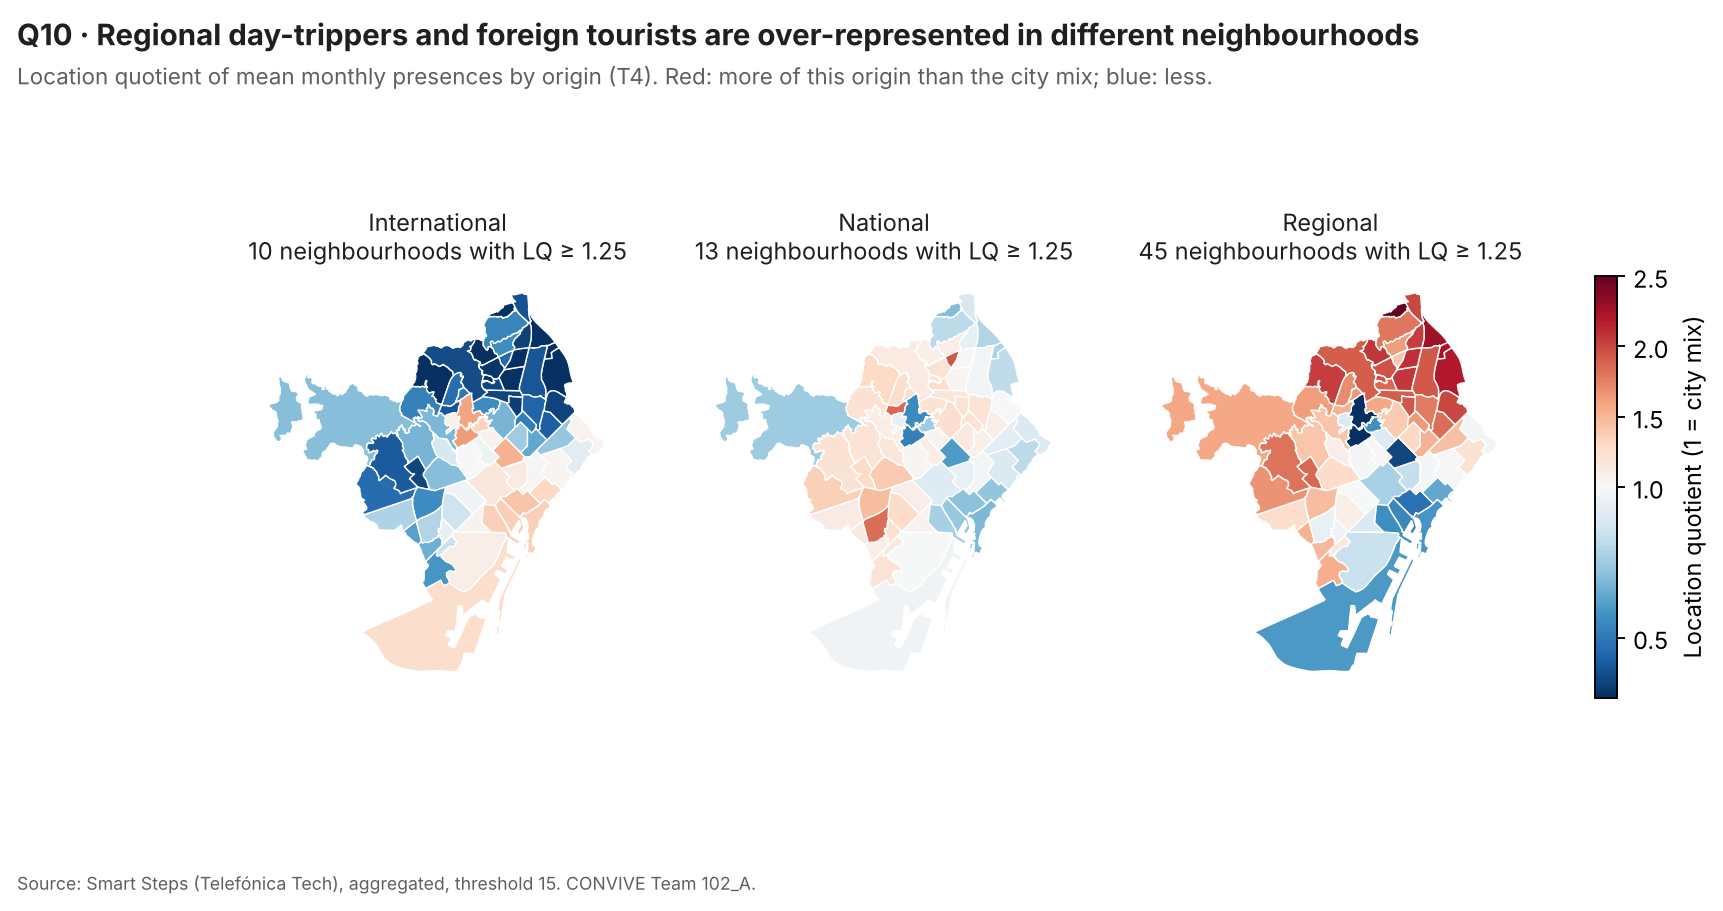

In [33]:
Image(filename=str(R.OUT / "figures" / "q10_lq_maps.png"))

### 3.4 When (3.2.3 temporal analysis)

In [34]:
show("Q7")

### Q7 · Do at least half of the tourists of a week spend at most 2 nights?

*Belief:* “Tourists only stay for a weekend.”  
*Metric:* Share of weekly tourists by number of nights in the week  
*Decision rule:* The 'weekend tourist' belief holds if at least 50% of the tourists of a week spend at most 2 nights (T3).

**Answer.** In 2024, international tourists: 72.6% spend 1-2 nights in a week, 13.9% 4 or more (mean 2.1 nights); national tourists: 63.1% spend 1-2 nights in a week, 26.4% 4 or more (mean 2.6 nights).

**Verdict: Holds: most tourists stay 1-2 nights per week.**  
*Limitation:* Municipality level; national and international tourists only; nights within one week.

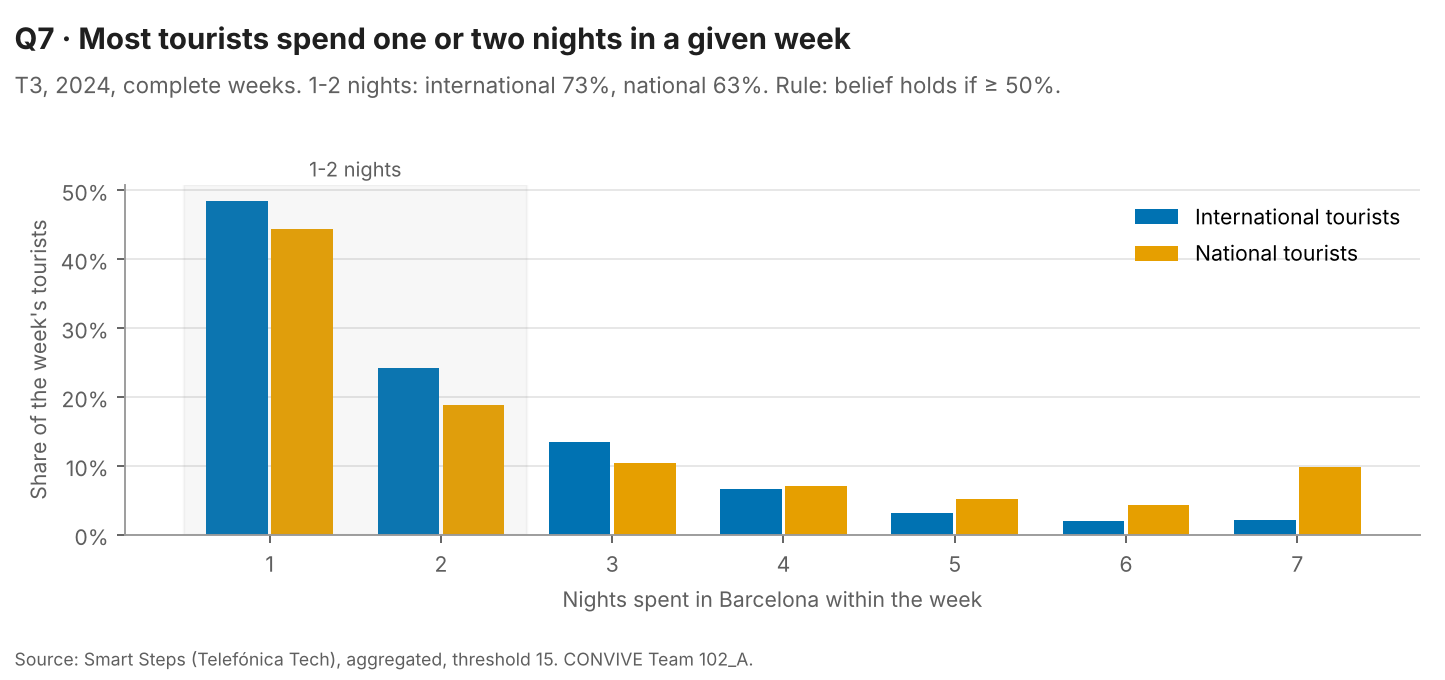

In [35]:
Image(filename=str(R.OUT / "figures" / "q7_nights.png"))

In [36]:
show("Q9")

### Q9 · Which days are at least 15% above (or below) the same weekday of the same month?

*Belief:* “Big events and holidays create visible peaks.”  
*Metric:* Daily unique visitors vs the median of the same weekday in the same month  
*Decision rule:* A day is an UNUSUAL PEAK if its unique visitors are at least 15% above the median of the same weekday in the same month (T2), and an UNUSUAL LOW if at least 15% below.

**Answer.** 7 of 971 days are unusual peaks (>= +15% vs the same weekday and month) and 25 unusual lows. Largest peaks: 2025-04-28 (Mon, +39.4%), 2023-04-23 (Sun, +33.3%), 2023-09-18 (Mon, +17.6%), 2024-12-30 (Mon, +17.3%). The data date the peaks; naming their cause needs an external event calendar.

**Verdict: 7 peak days and 25 low days found.**  
*Limitation:* The data date the peaks but cannot name their cause.

In [37]:
r['Q9']['peaks'][['date', 'weekday', 'visitantes', 'expected', 'deviation']].round(3)

,date,weekday,visitantes,expected,deviation
846,2025-04-28,Mon,779749,559421.0,0.394
112,2023-04-23,Sun,603366,452762.0,0.333
260,2023-09-18,Mon,549338,467026.5,0.176
728,2024-12-30,Mon,584916,498696.0,0.173
119,2023-04-30,Sun,524017,452762.0,0.157
721,2024-12-23,Mon,576218,498696.0,0.155
147,2023-05-28,Sun,554896,481291.0,0.153


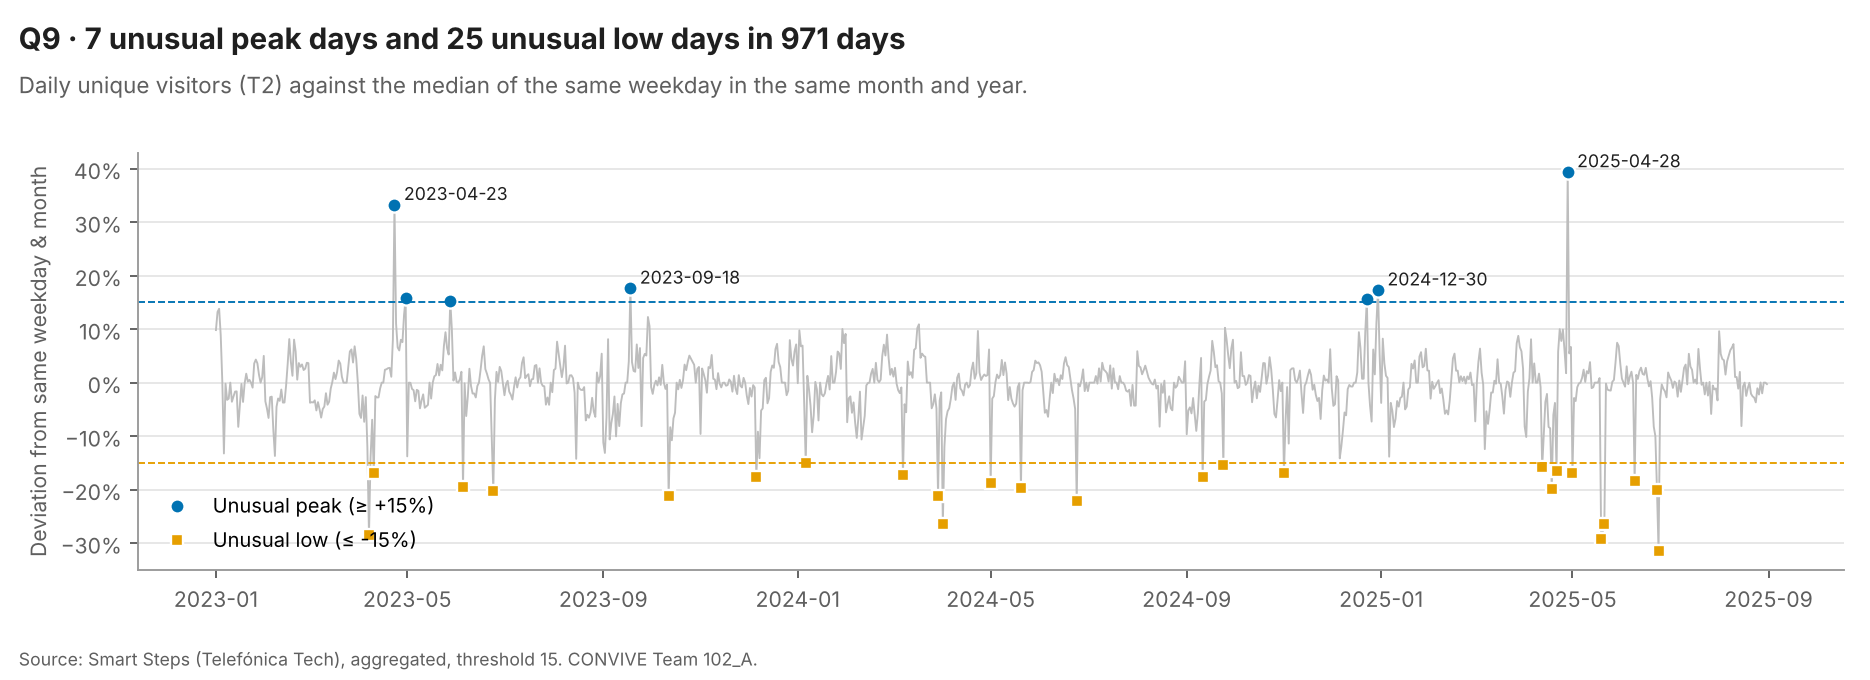

In [38]:
Image(filename=str(R.OUT / "figures" / "q9_unusual_days.png"))

In [39]:
show("Q15")

### Q15 · Do their weekday profiles differ by less than 5 points every day?

*Belief:* “Visitors and residents use the city at the same times.”  
*Metric:* Trips per day by weekday as an index (mean day = 100), visitors vs residents; same by month  
*Decision rule:* Visitors and residents use the city at the SAME TIMES if their weekday profiles (trips per day as an index, mean day = 100) differ by less than 5 points on every weekday (M1).

**Answer.** Weekday index (mean day = 100), visitors vs residents: Saturday 95 vs 79, Sunday 79 vs 64; largest gap 16 points (Sat). By month, visitors' trips peak in Oct (116) while residents' trips are lowest in Aug (65).

**Verdict: Different rhythms.**  
*Limitation:* Trips only; no hourly data.

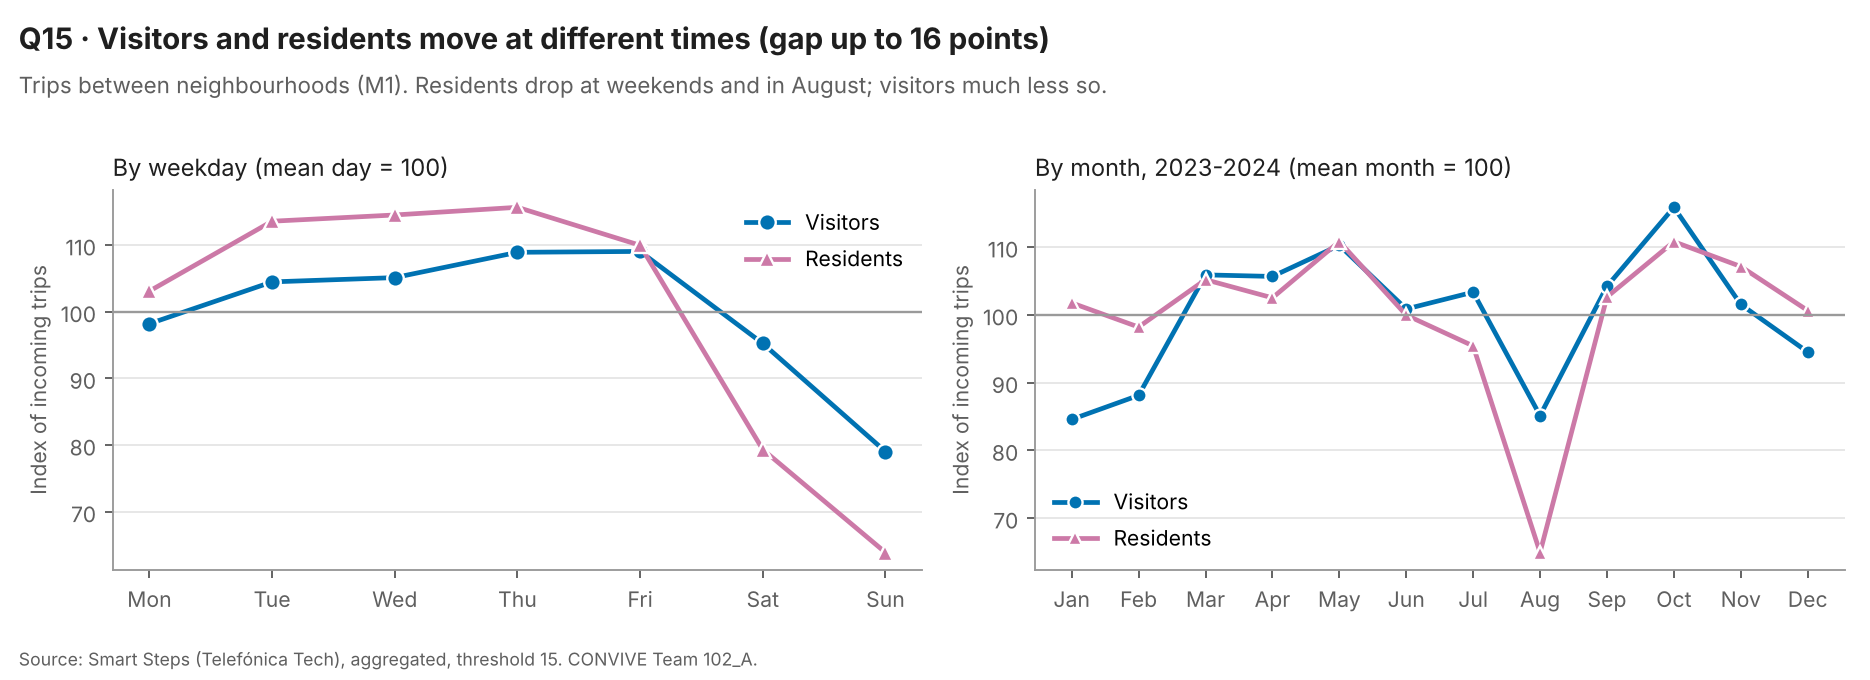

In [40]:
Image(filename=str(R.OUT / "figures" / "q15_rhythm.png"))

## 4. Neighbourhoods with very few data (I8)

Rule: mean monthly visitors below 10% of the median neighbourhood, or more than 15% of the T6-T8 rows grouped as NA.

In [41]:
low = r["low_data"]
low[low["low_data"]][["barrio_name", "distrito_name", "mean_monthly_visitors", "vs_median", "na_share_T8",
                      "resident_trips_vs_median", "visitor_share_trips", "reason"]].round(3)

,barrio_name,distrito_name,mean_monthly_visitors,vs_median,na_share_T8,resident_trips_vs_median,visitor_share_trips,reason
0,Verdun,Nou Barris,985.719,0.007,0.336,0.426,0.009,very low visitors + many grouped segments
1,la Teixonera,Horta-Guinardó,2760.656,0.021,0.172,0.588,0.025,very low visitors + many grouped segments
2,Ciutat Meridiana,Nou Barris,5209.000,0.039,0.276,0.259,0.080,very low visitors + many grouped segments
3,les Roquetes,Nou Barris,6567.344,0.049,0.066,0.289,0.027,very low visitors
4,el Coll,Gràcia,8673.250,0.065,0.044,0.236,0.061,very low visitors
5,Canyelles,Nou Barris,10013.969,0.074,0.094,0.126,0.063,very low visitors


The Business Manager asked us on 9 Nov to find out why some neighbourhoods have so few data (issue I8).

*Rule:* A neighbourhood is LOW-DATA if its mean monthly visitors (T4) are below 10% of the median neighbourhood, or if more than 15% of its rows in the origin files (T6, T7, T8) are grouped as NA (privacy threshold).

**6 of 73 neighbourhoods meet the rule**, all on the northern edge of the city (Nou Barris, Horta-Guinardó and Gràcia hills):

| Neighbourhood | District | Visitors per month (T4) | vs median | Max NA share T6-T8 | Residents' trips vs median | Visitor share of trips (M1) | Reason |
|---|---|---|---|---|---|---|---|
| Verdun | Nou Barris | 986 | 0.7% | 33.6% | 0.43 | 0.9% | very low visitors + many grouped segments |
| la Teixonera | Horta-Guinardó | 2,761 | 2.1% | 17.2% | 0.59 | 2.5% | very low visitors + many grouped segments |
| Ciutat Meridiana | Nou Barris | 5,209 | 3.9% | 27.6% | 0.26 | 8.0% | very low visitors + many grouped segments |
| les Roquetes | Nou Barris | 6,567 | 4.9% | 10.1% | 0.29 | 2.7% | very low visitors |
| el Coll | Gràcia | 8,673 | 6.5% | 8.8% | 0.24 | 6.1% | very low visitors |
| Canyelles | Nou Barris | 10,014 | 7.4% | 9.4% | 0.13 | 6.3% | very low visitors |

**What the data show.**

1. **It is not a loading or code error.** The 73 codes match their names in every month of M1 (2.2.2 check 14), every file has its 32 months
   and T5 has data for Verdun on all 971 days. The low values come from Telefónica's files as published.
2. **Two kinds of "few data".** Most low-data neighbourhoods are small residential areas with few visitors, so many of their segments fall under
   the privacy threshold of 15 and are grouped as NA (e.g. 34% of Verdun's country rows). This is expected behaviour of the anonymisation.
3. **Verdun and la Teixonera are different: they are outliers, not just small.** Their residents' trips are normal (0.43x and
   0.59x the median neighbourhood), but visitors are only 0.7% and 2.1% of the median. Their neighbour la Prosperitat,
   with a similar number of residents' trips (0.37x), has 61 times more visitors than Verdun.
   The visitor share of incoming trips is 0.9% in Verdun and 2.5% in la Teixonera (city: 44.7%).
4. **Two independent products agree.** T4 (people) and M1 (trips) are built differently, and both show almost no visitors there. So the cause lies upstream
   of both, in how Telefónica assigns visitors to these two areas, or in the areas themselves.
5. **Verdun has a break in its series.** Its visitors fall from 1,316 to 222 between July 2023 and August 2023 (-83%),
   and the mean before the break (1,805 per month) is 2.4 times the mean after it (756). No neighbour shows this step
   (la Teixonera, les Roquetes and la Prosperitat stay level), so the break suggests a change in how Verdun is measured rather than a real collapse of visitors (to confirm with the BM).
   Even before the break, Verdun was far below its neighbours. Coefficient of variation: 0.62 (la Teixonera 0.18).

**Hypotheses we cannot test with these data** (to ask the Business Manager / Telefónica, recorded as I8 in the F/U register):
(a) the network-coverage areas used to place people are assigned to the neighbouring neighbourhoods; (b) the visitor classification (people whose
residence is outside Barcelona) leaves very few people in two purely residential areas; (c) a known limitation of the Smart Steps zoning.

**Decision for the analysis.** Low-data neighbourhoods stay in every table and map, flagged. They are excluded only where a ratio would be
unstable: change rates (base of 1,000 visitors, Q5) and rankings at the bottom. The dashboard shows the flag next to their values.

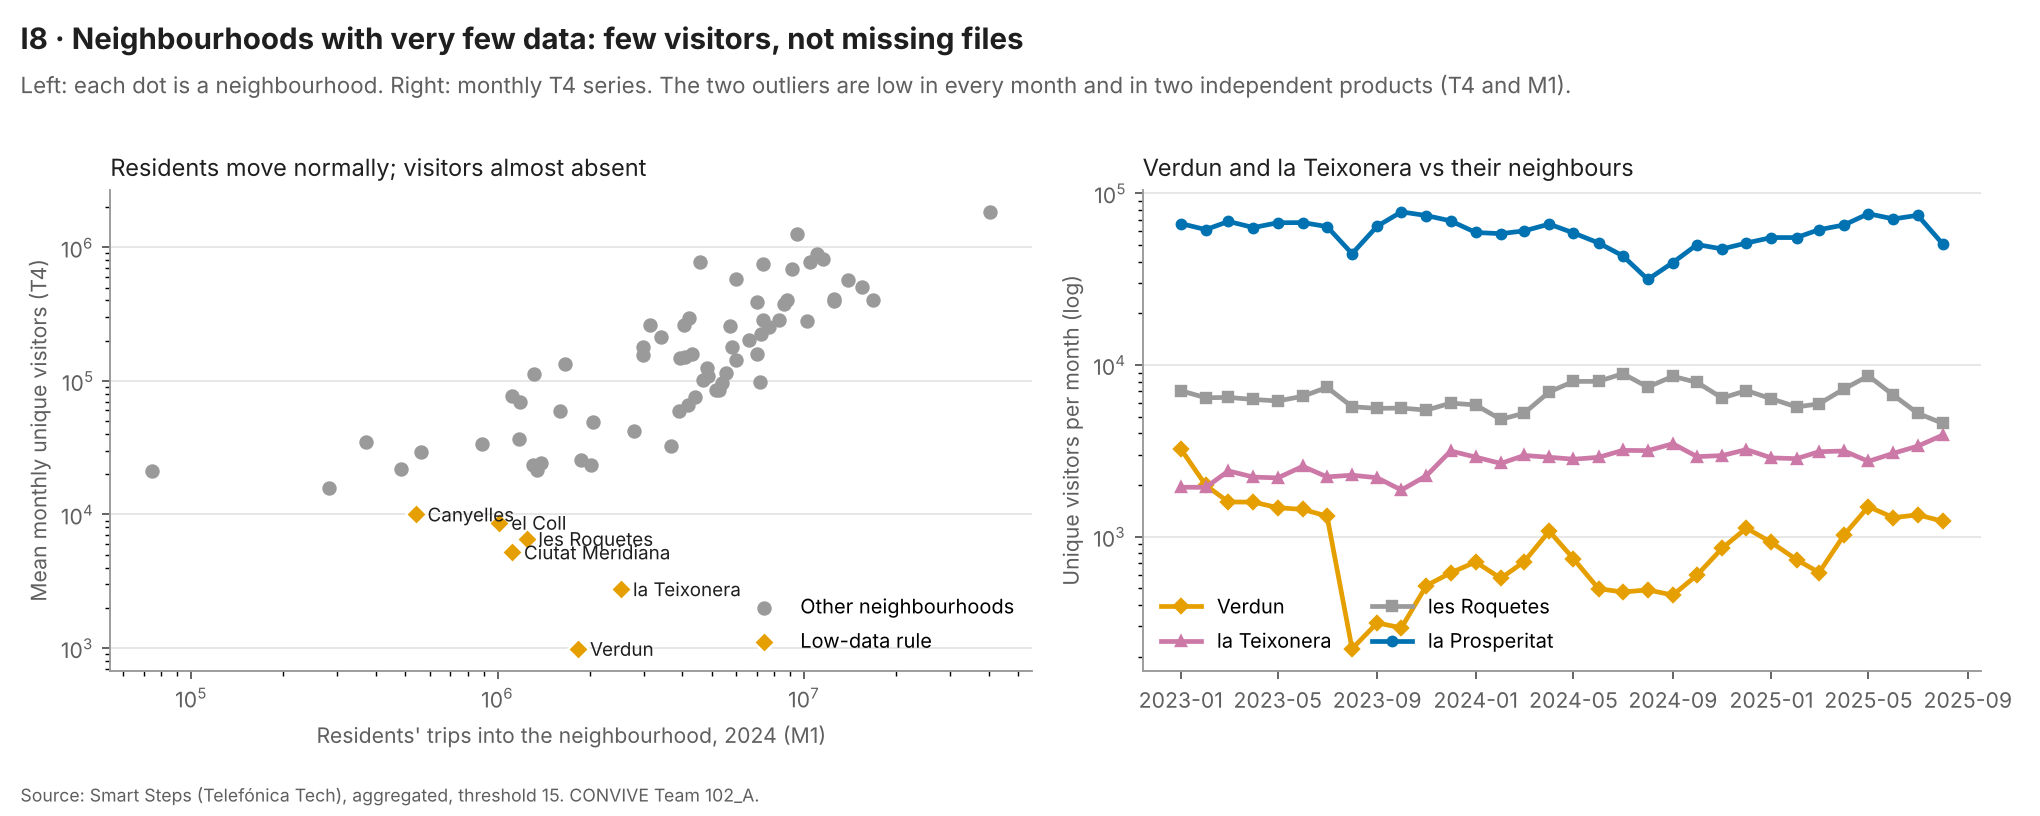

In [42]:
display(Markdown(RR.low_data_md(r, t)))
Image(filename=str(R.OUT / "figures" / "low_data_barris.png"))

## 5. Outputs written

`python research_report.py` (or this notebook) writes the Markdown reports 3.2.0-3.2.4, the CSV tables and the figures in `deliverables/iteration3/`. The dashboard (`streamlit run app/dashboard.py`) reads the same tables.

In [43]:
RR.write_all(t, r)
sorted(p.name for p in R.OUT.glob("*.md"))

  3.2.4_quantified_answers.md
  3.2.1_exploratory_analysis.md
  3.2.2_geographic_analysis.md
  3.2.3_temporal_analysis.md
  3.2.0_ResearchQuestions_v0.3.md


['2.2.2_validation_log.md',
 '3.2.0_ResearchQuestions_v0.3.md',
 '3.2.1_exploratory_analysis.md',
 '3.2.2_geographic_analysis.md',
 '3.2.3_temporal_analysis.md',
 '3.2.4_quantified_answers.md']